# Maven Fuzzy Factory — Landing Page A/B Test

## Objective

Analyze an A/B test comparing the original `/home` landing page with the new `/lander-1` landing page.

The analysis focuses on:

- Identifying control and test traffic
- Comparing bounce rates
- Testing statistical significance
- Providing a business recommendation

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt

## Define the A/B test results
Since the SQL analysis is already complete, use the final SQL results

In [2]:
control_sessions = 13683
control_bounces = 5837

test_sessions = 47543
test_bounces = 25310

## Calculate bounce rates

In [3]:
control_rate = control_bounces / control_sessions
test_rate = test_bounces / test_sessions

print(f"Control (/home) Bounce Rate: {control_rate:.2%}")
print(f"Test (/lander-1) Bounce Rate: {test_rate:.2%}")

Control (/home) Bounce Rate: 42.66%
Test (/lander-1) Bounce Rate: 53.24%


## Calculate the difference

In [4]:
difference = test_rate - control_rate

print(f"Bounce Rate Difference: {difference:.2%}")
print(f"Difference in percentage points: {difference * 100:.2f}")

Bounce Rate Difference: 10.58%
Difference in percentage points: 10.58


## Hypothesis test

In [5]:
# Null hypothesis:
# Control bounce rate = Test bounce rate

# Alternative hypothesis:
# Control bounce rate != Test bounce rate

pooled_rate = (
    control_bounces + test_bounces
) / (
    control_sessions + test_sessions
)

standard_error = math.sqrt(
    pooled_rate * (1 - pooled_rate) *
    (1 / control_sessions + 1 / test_sessions)
)

z_score = (control_rate - test_rate) / standard_error

p_value = math.erfc(
    abs(z_score) / math.sqrt(2)
)

print(f"Z-score: {z_score:.4f}")
print(f"P-value: {p_value:.10f}")

Z-score: -21.8089
P-value: 0.0000000000


## Decision

In [6]:
alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant")
else:
    print("Result: Not statistically significant")

Result: Statistically significant


## Business Recommendation

The `/lander-1` landing page has a bounce rate of **53.24%**, compared with **42.66%** for the original `/home` page.

The difference of **10.58 percentage points** is statistically significant (p < 0.05).

Therefore, the test landing page performed significantly worse than the original landing page.

### Recommendation

Keep the original `/home` landing page rather than `/lander-1`.

## Visualization

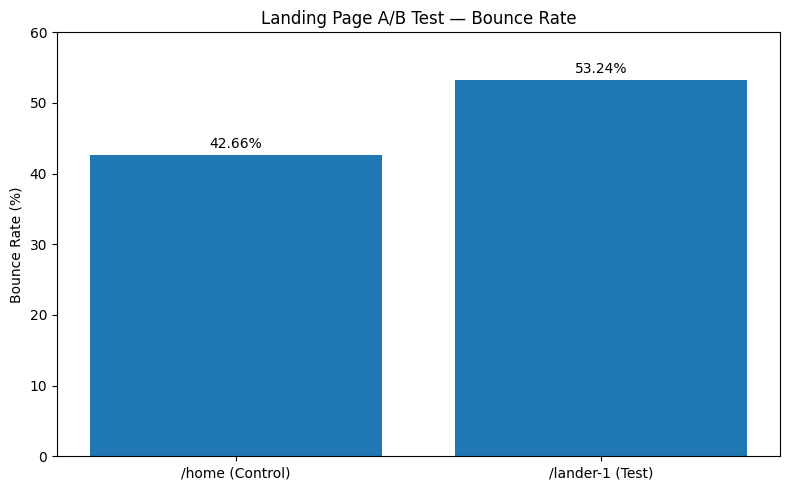

In [7]:
labels = ["/home (Control)", "/lander-1 (Test)"]
bounce_rates = [control_rate * 100, test_rate * 100]

plt.figure(figsize=(8, 5))
plt.bar(labels, bounce_rates)

plt.ylabel("Bounce Rate (%)")
plt.title("Landing Page A/B Test — Bounce Rate")
plt.ylim(0, 60)

for i, value in enumerate(bounce_rates):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()